# Lab 3: Developing a Tiny Transformer Language Model
**Module:** PUSL 3205 - Large Language Models and Generative AI

**Goal:** build a small GPT-style Transformer from scratch in PyTorch, train it on stories from the TinyStories dataset, measure how well it predicts the next character, and use it to generate new stories.

**The one idea behind everything:** the model reads some text and predicts the *next character*. Training repeats this millions of times until it gets good at it. Generating a story is just predicting the next character again and again.

**How this notebook is organised:** each task has (1) a short explanation, (2) the code, and (3) a "How the code works" note. Observation cells are left for you to write in your own words after you see your own results.

In [1]:
import itertools, json, math, os, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn import functional as F

os.makedirs("outputs", exist_ok=True)      # folder for saved plots and sample text
torch.manual_seed(1337)                    # fixed seeds so results are repeatable
random.seed(1337)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch version:", torch.__version__)
print("Using device:", device)

PyTorch version: 2.15.0+cpu
Using device: cpu


**How the code works:** `torch` is the deep-learning library. `nn` holds the building blocks of neural networks, and `F` holds functions such as softmax and cross-entropy. `device` picks the GPU if you have one, otherwise the CPU. The seeds make random numbers repeatable, so you get similar results each run.

## Task 1: Load and explore the dataset

**What this task does:** TinyStories is a Hugging Face dataset of short, simple stories written for young children. We load a small part of it and study it before using it.

**Why only 2,000 stories?** A full model needs huge data and a GPU. For a laptop lab, a small subset trains in minutes.

In [2]:
from datasets import load_dataset

N_STORIES = 2000
stream = load_dataset("roneneldan/TinyStories", split="train", streaming=True)
stories = [row["text"] for row in itertools.islice(stream, N_STORIES)]
print("Stories loaded:", len(stories))

C:\Users\Tharushi\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Stories loaded: 2000


**How the code works:**
- `load_dataset("roneneldan/TinyStories", ...)` fetches the dataset from Hugging Face.
- `streaming=True` reads stories one by one instead of downloading the whole multi-GB dataset.
- `itertools.islice(stream, 2000)` stops after the first 2,000 stories.
- `row["text"]` is the story text. The list comprehension collects them into the list `stories`.

In [3]:
for i in range(3):
    print(f"--- Story {i} ---")
    print(stories[i][:500])
    print()

--- Story 0 ---
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them b

--- Story 1 ---
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had many leaves that were falling. Beep liked how the leaves fall and wanted to play with them. Beep drove under the tree and watched the leaves fall on him. He laughed and beeped his horn.

Beep played w

**How the code works:** prints the first 500 characters of three stories so we can see the style: short sentences, simple words and a clear storyline.

Characters per story: min 274, mean 850, max 4123
Words per story:      min 61, mean 166, max 837
Average line breaks per story: 8.0


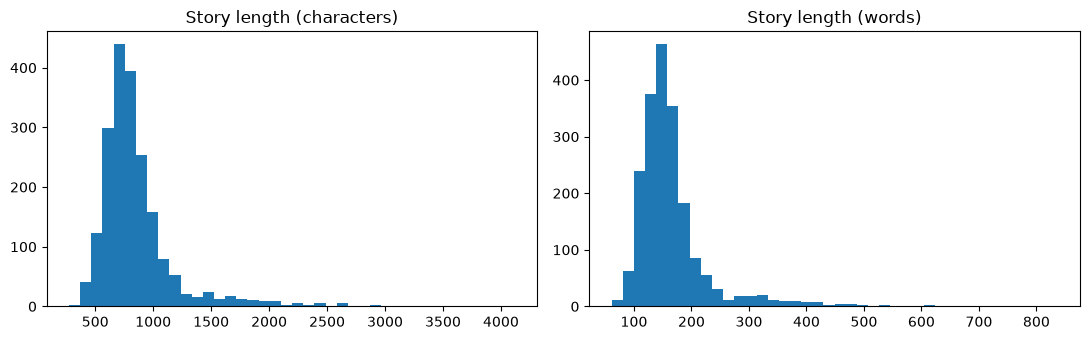

In [4]:
char_lens = [len(s) for s in stories]
word_lens = [len(s.split()) for s in stories]

print(f"Characters per story: min {min(char_lens)}, mean {np.mean(char_lens):.0f}, max {max(char_lens)}")
print(f"Words per story:      min {min(word_lens)}, mean {np.mean(word_lens):.0f}, max {max(word_lens)}")
print(f"Average line breaks per story: {np.mean([s.count(chr(10)) for s in stories]):.1f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(char_lens, bins=40); ax[0].set_title("Story length (characters)")
ax[1].hist(word_lens, bins=40); ax[1].set_title("Story length (words)")
plt.tight_layout()
plt.savefig("outputs/story_length_hist.png", dpi=150, bbox_inches="tight")
plt.show()

**How the code works:** `len(s)` counts characters and `len(s.split())` counts words in each story. `chr(10)` is the line-break character, so `s.count(chr(10))` counts line breaks (paragraph structure). The histograms show how story lengths are spread. `savefig` saves the plot to the `outputs` folder, and it must come *before* `plt.show()`.

**Observations** 
The stories are short and written in very simple language for young children. Each one has a named character (such as Lily, Beep the car and Fin the fish), a small problem and a helpful or happy ending, and several include dialogue in quotation marks. Paragraphs are separated by blank lines, and stories often begin with "One day" or "Once upon a time". On average a story has about 850 characters and 166 words (minimum 274 characters and 61 words, maximum 4,123 characters and 837 words), with about 8 line breaks per story. The histograms are skewed to the right: most stories are between roughly 600 and 1,000 characters long, with a peak near 700 to 800, while a small number of much longer stories form a tail up to about 4,000 characters. Because the language is simple and repetitive, a small model has a reasonable chance of learning some of its patterns. The typical story is also much longer than the 128-character context window I use later, so the model only ever sees a short piece of a story at a time.

## Task 2: Preprocess the text (character-level tokenization)

**What this task does:** a neural network works with numbers, not letters. *Tokenization* turns text into numbers. We use the simplest kind, **character level**: every distinct character (a, b, space, comma, ...) gets its own number.

**Why character level?** It needs no extra tokenizer library and the vocabulary is tiny (around 100 characters). The downside is that the model must learn to spell words letter by letter.

In [5]:
SEP = "\n\n"   # separator placed between stories

# split BEFORE encoding: 90% of stories for training, 10% for validation
n_train_stories = int(0.9 * len(stories))
train_text = SEP.join(stories[:n_train_stories])
val_text = SEP.join(stories[n_train_stories:])
text = train_text + SEP + val_text

chars = sorted(set(text))                 # every distinct character
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}    # character -> number
itos = {i: c for c, i in stoi.items()}        # number -> character

def encode(s):
    return [stoi[c] for c in s if c in stoi]

def decode(ids):
    return "".join(itos[i] for i in ids)

print("Vocabulary size:", vocab_size)
print("Encoded:", encode("Once upon a time")[:10], "...")
print("Decoded back:", decode(encode("Once upon a time")))

train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data = torch.tensor(encode(val_text), dtype=torch.long)
print("Training characters:", len(train_data))
print("Validation characters:", len(val_data))

Vocabulary size: 80
Encoded: [34, 59, 48, 50, 1, 66, 61, 60, 59, 1] ...
Decoded back: Once upon a time
Training characters: 1539169
Validation characters: 165747


**How the code works:**
- `sorted(set(text))` finds every unique character. `vocab_size` is how many there are.
- `stoi` ("string to integer") and `itos` ("integer to string") are lookup tables for the two directions.
- `encode` turns a string into a list of numbers, and `decode` turns numbers back into text. Decoding an encoded string should give the original text back, which confirms it works.
- The stories are split into **training (90%)** and **validation (10%)** *before* encoding. The model learns from training data. The validation data is never trained on, so it tells us honestly how well the model handles text it has not seen.
- `torch.tensor(...)` stores the numbers in a PyTorch tensor, the format the model needs.

**Observations:** I used character-level tokenization, so every distinct character in the 2,000 stories gets its own number. The vocabulary has 80 characters: upper and lower case letters, digits, punctuation, the space and the line break, plus a few unusual symbols that come from garbled characters in the dataset (such as â, € and ™, which also appeared in my generated text). In the encoded example, "Once upon a time" becomes [34, 59, 48, 50, 1, 66, 61, 60, 59, 1], and the same character always gets the same number (for example, n is 59 and the space is 1). Decoding the numbers returned the original text exactly, which shows that the encoding works in both directions. The data has 1,539,169 characters for training and 165,747 for validation, about a 90/10 split. I split by story before encoding, so the validation stories are never used for training and give an honest measure of how well the model handles unseen text. A small vocabulary of 80 means the output layer only has to choose between 80 characters, but the model has to learn to spell every word from scratch.

## Task 3: Prepare the training data (next-token prediction)

**What this task does:** we build the learning examples. Each example is an **input** sequence and a **target** sequence. The target is the input shifted one character to the right, so at every position the correct answer is "the next character".

Example with input `Once up` and target `nce upo`:
- after `O` the answer is `n`
- after `On` the answer is `c`
- after `Onc` the answer is `e`, and so on.

One sequence therefore gives many predictions at once.

In [6]:
block_size = 128    # how many characters the model sees at once (its context length)
batch_size = 16 # how many sequences we train on at the same time

def get_batch(split):
    data = train_data if split == "train" else val_data
    ix = torch.randint(len(data) - block_size - 1, (batch_size,))        # random start positions
    x = torch.stack([data[i:i + block_size] for i in ix])                # inputs
    y = torch.stack([data[i + 1:i + block_size + 1] for i in ix])        # targets: shifted by 1
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Input batch shape :", xb.shape)
print("Target batch shape:", yb.shape)
print("Input :", repr(decode(xb[0][:60].tolist())))
print("Target:", repr(decode(yb[0][:60].tolist())))

Input batch shape : torch.Size([16, 128])
Target batch shape: torch.Size([16, 128])
Input : ' was filled with laughter and smiles. \n\nEventually, the bear'
Target: 'was filled with laughter and smiles. \n\nEventually, the bears'


**How the code works:**
- `block_size = 128` means the model looks at up to 128 characters of context.
- `get_batch` picks 16 random positions in the data and cuts out a window of 128 characters starting at each. That window is `x`.
- `y` is the same window shifted by one character, so `y[t]` is the correct next character after `x[t]`.
- The shapes are `[16, 128]`: 16 sequences of 128 numbers each.
- Printing the first 60 characters of `x` and `y` shows the one-character shift. The target looks like the input moved along by one letter.
- 
**observation**
  Each training example is a window of 128 characters taken from a random position in the training text, and the target is the same window moved one character to the right. The batch shape is [16, 128] for both inputs and targets, meaning 16 sequences of 128 characters each (I lowered the batch size from 32 to 16 to make training lighter on my laptop). In the printed example, the input starts with a space (" was filled with laughter...") and the target starts with "w", and the input ends with "the bear" while the target ends with "the bears". So at every position the correct answer is the next character: after " " the answer is "w", after " w" it is "a", and so on, and at the end "bear" is followed by "s". One sequence therefore gives 128 prediction tasks at once. The window can start in the middle of a word or sentence, so the model learns to predict from whatever context it is given.



## Task 4: Build the Transformer architecture

A Transformer is built from a few parts. Here is what each one does:

| Part | Job |
|---|---|
| **Token embedding** | Turns each character number into a vector of numbers the model can work with |
| **Positional embedding** | Tells the model the *order* of the characters (attention alone does not know order) |
| **Masked multi-head self-attention** | Lets each character look at earlier characters to gather context |
| **Feed-forward layer** | Processes each position further, adding thinking power |
| **Residual connection** | Adds the input back to the output, so information and gradients flow easily |
| **Layer normalization** | Keeps the numbers at a stable scale so training is steady |

We build it in three steps: the attention layer, one Transformer block, then the full model.

In [7]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        assert n_embd % n_head == 0, "n_embd must be divisible by n_head"
        self.n_head = n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd)     # makes queries, keys and values together
        self.proj = nn.Linear(n_embd, n_embd)        # mixes the heads back together
        self.attn_drop = nn.Dropout(dropout)
        self.resid_drop = nn.Dropout(dropout)
        # lower-triangular matrix of ones: position t may only look at positions <= t
        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size)).view(1, 1, block_size, block_size))

    def forward(self, x):
        B, T, C = x.shape                            # batch, time (sequence length), channels (embedding size)
        q, k, v = self.qkv(x).split(C, dim=2)
        hs = C // self.n_head                        # size of each head
        q = q.view(B, T, self.n_head, hs).transpose(1, 2)
        k = k.view(B, T, self.n_head, hs).transpose(1, 2)
        v = v.view(B, T, self.n_head, hs).transpose(1, 2)

        att = (q @ k.transpose(-2, -1)) * (hs ** -0.5)               # how much each position matches each other one
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))   # hide the future
        att = F.softmax(att, dim=-1)                                 # turn scores into weights that sum to 1
        att = self.attn_drop(att)
        y = att @ v                                                  # weighted mix of the values
        y = y.transpose(1, 2).contiguous().view(B, T, C)             # put the heads side by side again
        return self.resid_drop(self.proj(y))

**How the attention layer works:**
- Each character produces three vectors: a **query** ("what am I looking for?"), a **key** ("what do I contain?") and a **value** ("what information do I give?").
- `q @ k.T` scores how well each query matches each key. Dividing by `sqrt(head size)` keeps the scores from getting too large.
- **The mask:** `masked_fill(..., -inf)` blocks every position from seeing later positions. Without it the model could simply read the answer from the future during training. After softmax, the blocked positions get weight 0.
- `softmax` turns the scores into weights that add up to 1, and `att @ v` uses them to take a weighted average of the values.
- **Multi-head:** the embedding is split into `n_head` smaller pieces and attention runs on each independently. Different heads can learn different patterns, such as the previous letter, the current word or punctuation.
- `proj` combines the heads, and dropout randomly switches off some values during training to reduce overfitting.

In [8]:
class Block(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffn = nn.Sequential(                    # feed-forward network
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # normalise, attend, then ADD the input back (residual)
        x = x + self.ffn(self.ln2(x))    # normalise, feed-forward, then ADD the input back (residual)
        return x

**How a Transformer block works:** a block does two things in order: attention (gather information from earlier characters) and a feed-forward network (process it). Each is wrapped with:
- **Layer normalization** (`ln1`, `ln2`) before it, to keep values stable.
- A **residual connection** (`x = x + ...`) after it, so the original input is added back. This lets information skip past a layer and makes deeper stacks of blocks trainable.
- The feed-forward network widens the vector 4 times, applies the **GELU** activation (a smooth non-linearity), then shrinks it back.

In [9]:
class TinyTransformer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.block_size = cfg["block_size"]
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["n_embd"])    # token embeddings
        self.pos_emb = nn.Embedding(cfg["block_size"], cfg["n_embd"])    # positional embeddings
        self.drop = nn.Dropout(cfg["dropout"])
        self.blocks = nn.Sequential(*[
            Block(cfg["n_embd"], cfg["n_head"], cfg["block_size"], cfg["dropout"])
            for _ in range(cfg["n_layer"])
        ])
        self.ln_f = nn.LayerNorm(cfg["n_embd"])
        self.head = nn.Linear(cfg["n_embd"], cfg["vocab_size"])          # scores for every possible next character
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))    # what the character is + where it is
        x = self.blocks(x)                                       # pass through the Transformer blocks
        logits = self.head(self.ln_f(x))                         # scores for the next character
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]                  # keep only the last block_size characters
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-6)    # scores for the LAST position only
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float("inf")       # keep only the top_k best choices
            probs = F.softmax(logits, dim=-1)
            nxt = torch.multinomial(probs, num_samples=1)         # sample one character
            idx = torch.cat([idx, nxt], dim=1)                    # add it and repeat
        return idx

**How the full model works:**
1. `tok_emb(idx)` turns each character number into a vector, and `pos_emb(pos)` adds a vector for its position. Adding them tells the model *what* the character is and *where* it is.
2. The vectors pass through `n_layer` Transformer blocks.
3. A final layer norm and `head` produce, for every position, a score for each of the `vocab_size` possible next characters. These scores are called **logits**.
4. If `targets` are given, `F.cross_entropy` compares the scores with the correct next characters and returns the **loss** (how wrong the model is).
5. `_init_weights` starts the weights as small random numbers.
6. `generate` writes new text: it predicts the next-character scores, picks one character, adds it to the text, and repeats. The details of temperature and top-k are covered in Task 9.



## Task 5: Initialize the model, loss function and optimizer

**What this task does:** choose the model size (the *configuration*), create the model, and set up how it will learn.

- **Loss function: cross-entropy.** It measures how far the predicted next-character probabilities are from the correct answer. It is computed inside `forward`.
- **Optimizer: AdamW.** It updates the model's weights to reduce the loss. It is created inside the training function in Task 6.

In [10]:
config = dict(
    vocab_size=vocab_size,
    block_size=block_size,
    n_layer=4,       # number of Transformer blocks
    n_head=4,        # attention heads per block
    n_embd=128,      # size of each character's vector
    dropout=0.1,     # fraction of values randomly switched off during training
)

model = TinyTransformer(config).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {n_params:,}")

x0, y0 = get_batch("train")
_, loss0 = model(x0, y0)
print(f"Initial loss: {loss0.item():.3f}")
print(f"Loss expected from pure random guessing: {math.log(vocab_size):.3f}")

Model parameters: 830,288
Initial loss: 4.377
Loss expected from pure random guessing: 4.382


**How the code works:**
- `config` holds the model settings. These are the numbers we change in Task 10.
- `n_params` counts the learnable numbers in the model. More layers or a larger embedding means more parameters.
- **A useful sanity check:** before training, the model knows nothing, so it is guessing at random between `vocab_size` characters. The expected loss is `ln(vocab_size)`. If your initial loss is close to that number, the model is wired up correctly.

**observation**
I used a Transformer with 4 layers, 4 attention heads, an embedding size of 128 and a dropout of 0.1. The context length is 128 characters and the vocabulary has 80 characters. This gives 830,288 learnable parameters. The loss function is cross-entropy, which compares the predicted probabilities for the next character with the correct one, and the optimizer is AdamW with a learning rate of 0.001. Before training, the loss was 4.377. With a vocabulary of 80 characters, a model that guesses completely at random would have a loss of ln(80) = 4.382, so the initial loss is almost exactly the random-guessing value. This shows the untrained model knows nothing yet and that the network is set up correctly. Training should then bring the loss well below this starting point.



## Tasks 6 and 7: Train the model and monitor the loss

**What training does.** Each step repeats five actions:
1. **Forward pass:** feed a batch in and get predictions.
2. **Loss:** compare the predictions with the targets using cross-entropy.
3. **Backpropagation (`loss.backward()`):** work out how each weight contributed to the error.
4. **Update (`optimizer.step()`):** adjust the weights a little to reduce the error.
5. **Repeat** many times.

**About "epochs" here:** we sample random windows of text, so one "epoch" in this notebook means `steps_per_epoch` training steps rather than one full pass over the data. After each epoch we record the **training loss** (on data the model learns from) and the **validation loss** (on data it never trains on).

**Tip:** do a quick test run with `epochs=2` first to make sure everything works, then run the full training.

In [ ]:
@torch.no_grad()
def estimate_loss(m, eval_batches=20):
    m.eval()                                  # turn dropout off for fair measurement
    out = {}
    for split in ["train", "val"]:
        losses = torch.zeros(eval_batches)
        for k in range(eval_batches):
            xb, yb = get_batch(split)
            _, loss = m(xb, yb)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    m.train()
    return out


def train_model(cfg, epochs=10, steps_per_epoch=100, lr=1e-3, verbose=True):
    m = TinyTransformer(cfg).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr)
    history = {"train": [], "val": []}
    start = time.time()
    for epoch in range(1, epochs + 1):
        m.train()
        for _ in range(steps_per_epoch):
            xb, yb = get_batch("train")
            _, loss = m(xb, yb)                                # forward pass and loss
            opt.zero_grad(set_to_none=True)                    # clear old gradients
            loss.backward()                                    # backpropagation
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)  # stop gradients getting too big
            opt.step()                                         # update the weights
        losses = estimate_loss(m)
        history["train"].append(losses["train"])
        history["val"].append(losses["val"])
        if verbose:
            print(f"Epoch {epoch}/{epochs} | train loss {losses['train']:.3f} | val loss {losses['val']:.3f} | {time.time() - start:.0f}s")
    return m, history

**How the code works:**
- `estimate_loss` averages the loss over several batches for both training and validation data. `m.eval()` switches off dropout so the measurement is not noisy, and `m.train()` switches it back on.
- In `train_model`, the inner loop is the five-action training step above. `zero_grad` clears the previous step's gradients, `backward` computes new ones, `clip_grad_norm_` caps very large gradients (which keeps training stable), and `opt.step()` updates the weights.
- `lr=1e-3` is the learning rate, the size of each update. Too high is unstable, and too low is slow.
- Each epoch ends by recording the training and validation loss in `history` and printing them.

In [15]:
# Quick test first: change epochs to 2 to check that everything works, then use 10 for the real run
model, history = train_model(config, epochs=10, steps_per_epoch=100)

Epoch 1/10 | train loss 2.339 | val loss 2.375 | 93s
Epoch 2/10 | train loss 2.255 | val loss 2.300 | 184s
Epoch 3/10 | train loss 2.223 | val loss 2.261 | 272s
Epoch 4/10 | train loss 2.050 | val loss 2.078 | 363s
Epoch 5/10 | train loss 1.860 | val loss 1.910 | 456s
Epoch 6/10 | train loss 1.734 | val loss 1.794 | 660s
Epoch 7/10 | train loss 1.623 | val loss 1.690 | 753s
Epoch 8/10 | train loss 1.544 | val loss 1.602 | 842s
Epoch 9/10 | train loss 1.519 | val loss 1.553 | 935s
Epoch 10/10 | train loss 1.468 | val loss 1.528 | 1026s


This cell takes the longest. On a CPU it can take several minutes, and it is much faster on a GPU or in Google Colab. If it is too slow, lower `steps_per_epoch` to 100.

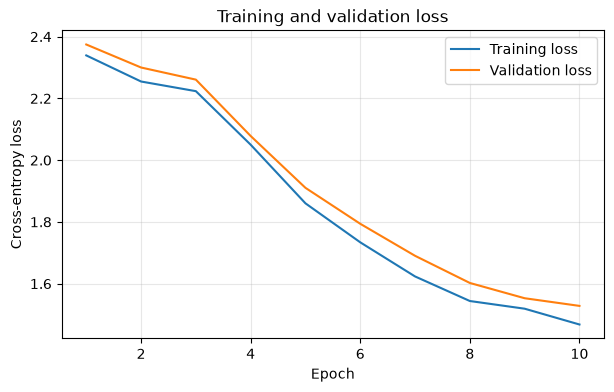

In [16]:
plt.figure(figsize=(7, 4))
epochs_axis = range(1, len(history["train"]) + 1)
plt.plot(epochs_axis, history["train"], label="Training loss")
plt.plot(epochs_axis, history["val"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training and validation loss")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("outputs/loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read the loss curves:**
- A falling line means the model is learning.
- If training loss keeps falling while validation loss flattens or rises, the model is **overfitting**: memorising the training text instead of learning general patterns.
- If both lines are close together and falling, the model is learning well.


**observation**
I trained the baseline model for 10 epochs of 100 steps each (1,000 steps in total, about 17 minutes on my laptop CPU). The training loss fell from 2.339 at epoch 1 to 1.468 at epoch 10, and the validation loss fell from 2.375 to 1.528, so the model clearly learned to predict the next character. The fall was slow at first (the loss changed little between epochs 2 and 3), fastest between epochs 3 and 6 (validation loss from 2.261 to 1.794), and then slowed down towards the end (the validation loss only dropped by 0.025 between epochs 9 and 10). The validation loss stayed slightly above the training loss throughout, with a gap of only about 0.03 to 0.07, and both lines moved down together. This means there is no sign of overfitting: the model is not just memorising the training stories and does about as well on stories it has never seen. The curves have not fully flattened by epoch 10, so training for longer would probably lower the loss further.


## Task 8: Evaluate the model (validation loss and perplexity)

**Perplexity = exp(validation loss).** It can be read as "how many characters the model is effectively choosing between at each step". A lower number means a more confident and accurate model.

- If the model guessed completely at random, its perplexity would equal the vocabulary size.
- A trained model should be well below that.

In [25]:
final = estimate_loss(model, eval_batches=50)
val_loss = final["val"]
perplexity = math.exp(val_loss)

print(f"Validation loss: {val_loss:.3f}")
print(f"Perplexity     : {perplexity:.2f}")
print(f"Random guessing would give perplexity about {vocab_size}")

Validation loss: 1.522
Perplexity     : 4.58
Random guessing would give perplexity about 80


**How the code works:** `estimate_loss` with 50 batches gives a steadier average of the validation loss. `math.exp(val_loss)` converts it to perplexity.

**observation**
On the validation stories, which the model never trained on, the final validation loss is 1.522 and the perplexity is exp(1.522) = 4.58. Perplexity can be read as the number of characters the model is effectively choosing between at each step. A model guessing at random would have a perplexity equal to the vocabulary size, which is 80, so my model is roughly 17 times more certain than guessing (80 divided by 4.58). The validation loss here (1.522) is very close to the last value in the training log (1.528). The small difference is because this evaluation averages over 50 batches instead of 20, so it is a slightly steadier estimate. A perplexity of 4.58 means the model has learned the common letter patterns, spelling and punctuation of these stories, but it is still unsure between a few characters at each step, so it cannot yet write fully correct text. More training steps, or a bigger model with more training, should lower the perplexity further.


## Task 9: Generate stories

**What this task does:** give the model a starting prompt and let it write the rest, one character at a time.

Two settings control the style:
- **Temperature:** low (about 0.5) means safe, repetitive text. High (about 1.2) means more creative but messier text.
- **Top-k:** the model only chooses between its `k` most likely next characters, which cuts out unlikely mistakes.

In [26]:
def generate_story(m, prompt="Once upon a time", max_new_tokens=400, temperature=0.8, top_k=40):
    m.eval()
    ids = encode(prompt)
    idx = torch.tensor([ids], dtype=torch.long, device=device)
    out = m.generate(idx, max_new_tokens, temperature, top_k)
    return decode(out[0].tolist())

samples = []
for prompt in ["Once upon a time", "One day, a little girl named Lily"]:
    story = generate_story(model, prompt)
    print("PROMPT:", prompt)
    print(story)
    print("-" * 60)
    samples.append(f"Prompt: {prompt}\n{story}\n")

PROMPT: Once upon a time
Once upon a time, Mia happy was so the wanted it to had at the prand hears and wated the came. She can boy. She come was a becamed to come detch backed on the brost the with boted to the nevery backs.

They fill was to not epcing pers was and and downed the come to are and play noted and witite. They hearved to to to glage jout were to stant to a big call so playing animiled to groughed help with she dound. They 
------------------------------------------------------------
PROMPT: One day, a little girl named Lily
One day, a little girl named Lily, a so had had her she fabind the sprid and so call make saw and couldn't with. He the was so exploxet it. She to his eardenly opencide booking and maked and were the with hung less it was and sing face and in its and safed and must.

Once upon a like, the with holled to playunna time ther a kide to sling she chould something had again, Jall of and the clowed and go the sprettener. Lilyone he les 
---------------------

**How the code works:** `generate_story` converts the prompt into numbers, calls the model's `generate` method (which predicts and appends characters one at a time), and converts the result back to text.

In [32]:
# Effect of temperature
for t in [0.5, 0.8, 1.2]:
    story = generate_story(model, "Once upon a time", max_new_tokens=250, temperature=t)
    print(f"Temperature {t}:")
    print(story)
    print("-" * 60)
    samples.append(f"Temperature {t}:\n{story}\n")

with open("outputs/generated_samples.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(samples))
print("Saved samples to outputs/generated_samples.txt")

Temperature 0.5:
Once upon a time, the like and here was a little was a like it to the was a big the was so like and the was a like to he parked the was her scare was a like and a looked the friend. She was to she was a like and and the she scare were like big it was he put and gain
------------------------------------------------------------
Temperature 0.8:
Once upon a time, a splay Timmys. He whome, thing will was a liked the had the picked it in han the kidn't wouldn't warl homething when was and his in the so to playing. It was up to little so  his to time, the liked every they comethind her, so he stice the day, sh
------------------------------------------------------------
Temperature 1.2:
Once upon a time trach, Hid rey wentuyed. She have mes.

Lily's so blu'r luquird with from. One danstle was the like olly that like! I proup becamed she at bira tigall canted the Everywhinc, a parked stantere wentuled in unna he clost and yarered.

"He,"

Rught thin
--------------------------

**Observations:** I generated stories with the trained model (temperature 0.8 and top-k 40 for the first two prompts, and top-k 40 for the temperature test). The text is not a readable story. It does look like English: the model has learned spelling patterns, many real short words ("the", "was", "she", "play", "big", "said", "come"), capital letters at the start of sentences, full stops, commas, quotation marks, paragraph breaks and character names such as Mia, Lily and Ben. It also reproduced the story opening, since "Once upon a" appears again in the middle of the text. But the model has not learned grammar or meaning. Sentences are not coherent ("She come was a becamed to come detch backed"), words repeat ("to to to", "the like the like"), and it invents words that do not exist ("prand", "wated", "exploxet", "junf"). Temperature changed the style clearly. At 0.5 the text was the most readable and used the most common words, but it was repetitive. At 0.8 it mixed in more made-up words. At 1.2 it was the most random, with strange names and odd punctuation such as "Mexmela", "Lacziles" and "camed.lly". The main model, trained for 1,000 steps, produced more real words than the experiment models trained for only 250 steps, whose output was mostly letter patterns. This matches a validation loss of about 1.5: the model has learned characters and words, but would need much more training, data and size to write real stories.

## Task 10: Experiment with model settings

**What this task does:** change one setting at a time and see how it affects the loss and the generated text. We train five versions with fewer epochs to keep the run time reasonable.

| Experiment | What changes |
|---|---|
| Baseline | 4 layers, 4 heads, 5 epochs |
| Fewer layers | 2 layers |
| More layers | 6 layers |
| More heads | 8 heads |
| More training | 10 epochs |

Changing one thing at a time is what makes this a fair comparison.

In [30]:
experiments = {
    "baseline (4 layers, 4 heads, 5 epochs)": (dict(config), 5),
    "fewer layers (2 layers)":                ({**config, "n_layer": 2}, 5),
    "more layers (6 layers)":                 ({**config, "n_layer": 6}, 5),
    "more heads (8 heads)":                   ({**config, "n_head": 8}, 5),
    "more training (10 epochs)":              (dict(config), 10),
}

results = {}
for name, (cfg, epochs) in experiments.items():
    print(f"\n=== {name} ===")
    m, h = train_model(cfg, epochs=epochs, steps_per_epoch=50, verbose=False)
    fin = estimate_loss(m, eval_batches=50)
    results[name] = {"history": h, "val_loss": fin["val"], "perplexity": math.exp(fin["val"]),
                     "params": sum(p.numel() for p in m.parameters()), "model": m}
    print(f"Parameters: {results[name]['params']:,} | val loss {fin['val']:.3f} | perplexity {math.exp(fin['val']):.2f}")
    print(generate_story(m, "Once upon a time", max_new_tokens=200))


=== baseline (4 layers, 4 heads, 5 epochs) ===
Parameters: 830,288 | val loss 2.268 | perplexity 9.66
Once upon a time wa thath.
She wa and d heap isur changon toved lay he buntod re tid hend aust t ayollledllory inustha yous. he tha he f t. The t Sor sig frore cithayound lamed hebithe ulait.



She t wowacimare ndon

=== fewer layers (2 layers) ===
Parameters: 433,744 | val loss 2.265 | perplexity 9.63
Once upon a time. The sililpped. they he lre ay wered mand ime ie toly. 


â€™soten smad pl Efroulo washe wartole way the wthe n anl bo wale ndin r lllo sk fing Lid hefithend he be ie bithebeasas f bsthene silitap t.

=== more layers (6 layers) ===
Parameters: 1,226,832 | val loss 2.272 | perplexity 9.70
Once upon a time tid go sthas to iangs im.
Oneant herl fat t aind igo tha wad wine che d bo ano bulpr!

Jerror a the he to he o be fed soungiler oontrrsow s a. I The s s therd a youpe gtowangop. shimed wango g at he 

=== more heads (8 heads) ===
Parameters: 830,288 | val loss 2.264 | 

**How the code works:** `experiments` maps a name to a pair of (model settings, number of epochs). `{**config, "n_layer": 2}` copies the baseline settings and changes only the number of layers. For each experiment the loop trains a fresh model, measures validation loss and perplexity, and prints a short generated sample. This cell trains five models, so it takes the longest.

Experiment                                        Params  Val loss  Perplexity
baseline (4 layers, 4 heads, 5 epochs)           830,288     2.268        9.66
fewer layers (2 layers)                          433,744     2.265        9.63
more layers (6 layers)                         1,226,832     2.272        9.70
more heads (8 heads)                             830,288     2.264        9.62
more training (10 epochs)                        830,288     1.891        6.63


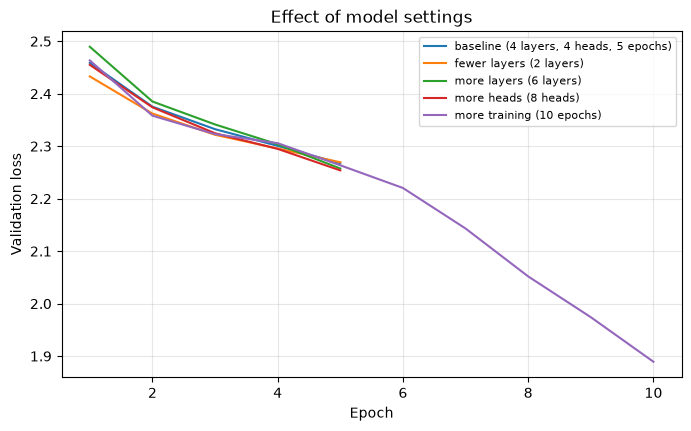

In [31]:
print(f"{'Experiment':45s} {'Params':>10s} {'Val loss':>9s} {'Perplexity':>11s}")
for name, r in results.items():
    print(f"{name:45s} {r['params']:>10,d} {r['val_loss']:>9.3f} {r['perplexity']:>11.2f}")

plt.figure(figsize=(8, 4.5))
for name, r in results.items():
    plt.plot(range(1, len(r["history"]["val"]) + 1), r["history"]["val"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Effect of model settings")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.savefig("outputs/experiment_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

I trained five models, each with 50 steps per epoch. The four models trained for 5 epochs (baseline, 2 layers, 6 layers and 8 heads) ended with almost the same validation loss (2.264 to 2.272, perplexity about 9.6 to 9.7). So changing the number of layers or heads made no clear difference at this short training length. The 6-layer model has 1,226,832 parameters, nearly three times the 433,744 of the 2-layer model, but it was not better. The 8-head model had the same number of parameters as the baseline (830,288), because more heads only split the same embedding into smaller pieces. Training for 10 epochs gave the biggest improvement: validation loss fell to 1.891 and perplexity to 6.63, and its text contained more real words such as "said", "was" and "the", although it was still not a coherent story. Note that the 10-epoch model also had twice as many training steps, so this compares training length and not model size. With a small training budget, training longer helped much more than making the model bigger.

## Task 11: Save the trained model

**What this task does:** save the model so it can generate text later without retraining. We save two things:
- the **parameters** (the learned weights) in a `.pt` file, and
- the **configuration** (model settings and the character-to-number table) in a JSON file. Both are needed to rebuild the model.

In [28]:
os.makedirs("saved_model", exist_ok=True)
torch.save(model.state_dict(), "saved_model/tiny_transformer.pt")
with open("saved_model/config.json", "w") as f:
    json.dump({"model_config": config, "stoi": stoi}, f)
print("Saved to the saved_model folder.")

Saved to the saved_model folder.


In [29]:
# Reload the saved model to prove it works
with open("saved_model/config.json") as f:
    saved = json.load(f)

loaded = TinyTransformer(saved["model_config"]).to(device)
loaded.load_state_dict(torch.load("saved_model/tiny_transformer.pt", map_location=device))
loaded.eval()
print(generate_story(loaded, "Once upon a time", max_new_tokens=200))

Once upon a time, "Mille to hould to the mommying she was hookay. The was a good so here and so the stall,â€œI'm. What is hole to trienday, cring is to girl his gain.

But is yhelp you with her. She happy. But smored


**How the code works:** `state_dict()` is the dictionary of all learned weights. To reload, we rebuild the same architecture from the saved configuration and load the weights into it. If the reloaded model writes sensible text, the save worked.

## Optional: Chat window with Gradio

Gradio makes a small web page for the model. You type a story starter, choose the length and temperature, and the model writes a story. Run `!pip install gradio` first if it is not installed.

In [ ]:
import gradio as gr

def story_fn(prompt, length, temperature):
    return generate_story(model, prompt or "Once upon a time", int(length), float(temperature))

demo = gr.Interface(
    fn=story_fn,
    inputs=[
        gr.Textbox(label="Story starter", value="Once upon a time"),
        gr.Slider(50, 600, value=300, step=50, label="Length (characters)"),
        gr.Slider(0.3, 1.5, value=0.8, step=0.1, label="Temperature"),
    ],
    outputs=gr.Textbox(label="Generated story", lines=12),
    title="Tiny Story Generator",
)
demo.launch()

## Discussion: mechanisms that improve performance

- **Self-attention** lets every position use information from earlier characters directly, so context from anywhere in the window can help the prediction.
- **Multi-head attention** lets the model look for different kinds of patterns at the same time.
- **Causal masking** stops the model peeking at future characters, so training matches the real task of predicting the next one.
- **Positional embeddings** give the model the order of the characters.
- **Residual connections** let information and gradients flow past each layer, which makes deeper models trainable.
- **Layer normalization** keeps values on a stable scale, so training is faster and steadier.
- **Feed-forward layers with GELU** add extra processing power at every position.
- **Dropout, gradient clipping and AdamW** reduce overfitting and keep training stable.
- **More data, a bigger model and longer training** usually lower the loss further, which is what the experiments explore.

(Add your own points based on what you saw in your experiments.)